In [16]:
# enable automatic reloading of the notebook
%load_ext autoreload
%autoreload 2

# Demo: sequences <-> networks
The following notebook provides a demonstration how the ts2g2 library can be used to convert time series into graphs and graphs into time series. To that end, we use a dataset with the history of daily prices of Amazon stock (AMZN) and Apple stock (APPLE). All the column desinpiptions are provided. Currency is USD.

In [1]:
import os, sys
sys.path.append("/var/scratch/sdu/ts2g2") #replace with your path to ts2g2
import warnings
import utils

from pipeline import T2G2Pipeline
from visualization import draw_g
from strategies.ts2g.strategy_builder import get_ts2g_strategy_builder
from strategies.view import get_view_strategy
from strategies.merge.strategy_linking_graph import StrategyLinkingGraphByValueWithinRange
from strategies.merge import get_link_nodes_strategy_builder
from strategies.merge import get_link_multigraph_strategy_builder
warnings.filterwarnings("ignore")


# Accessing data
We first get path to the data.

In [2]:
amazon_path = os.path.join(os.getcwd(), "amazon", "AMZN.csv")
apple_path = os.path.join(os.getcwd(), "apple", "APPLE.csv")

# Converting time series to graph
Here are two examples of conversion of data from time serie to graph. Second one is inpeated using sliding window mechanism. That means its nodes are smaller graphs inpeated based on a segments of data (length = 5).

Applying viewing strategy: <strategies.view.views.SliceView object at 0x7f674a344d40>
Number of dimensions: 1; total windows: 1


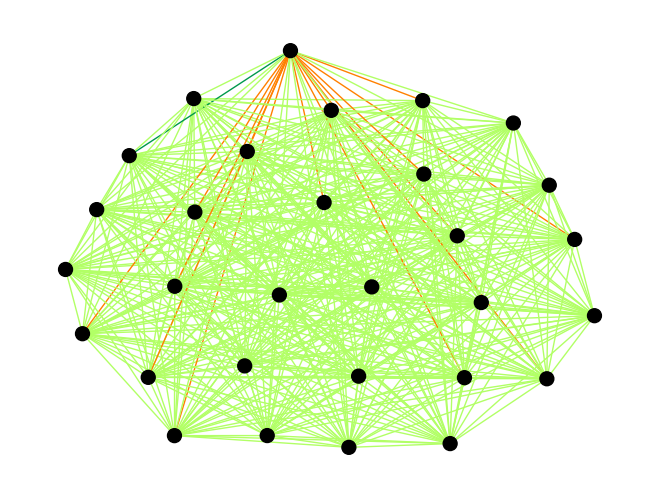

In [3]:
ts_data = utils.CsvFile(amazon_path, "Close").from_csv()

view_strategy = get_view_strategy("slice")(start_index=60, end_index=90)
builder_cls = get_ts2g_strategy_builder(method="natural_visibility")
ts2g_strategy = builder_cls().with_limit(1).get_strategy()

link_nodes_builder = get_link_nodes_strategy_builder()
link_nodes_strategy = (
    link_nodes_builder()
    .by_value(StrategyLinkingGraphByValueWithinRange(2))
    .seasonalities(15)
)

pipeline1 = T2G2Pipeline()
(
    pipeline1.load_timeseries(ts_data)
            .viewing(view_strategy)
            .to_graph(ts2g_strategy)
            .add_edge(0, 2)
            .add_edge(13, 21, weight=17)
            .link_nodes_within_graphs(link_nodes_strategy)
)

G = pipeline1.get_Graph()
draw_g(G)

Applying viewing strategy: <strategies.view.views.SliceView object at 0x7f674a140950>
Number of dimensions: 1; total windows: 1
Applying viewing strategy: <strategies.view.views.FixedOverlapWindow object at 0x7f68b73917f0>
Number of dimensions: 1; total windows: 56


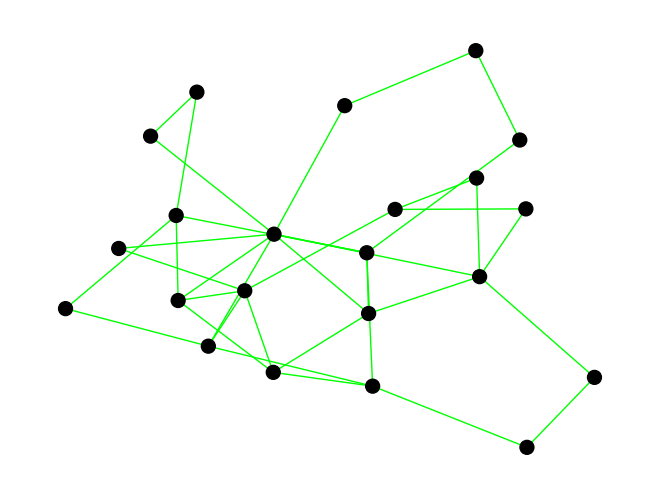

In [4]:
from strategies.merge import get_link_multigraph_strategy_builder

ts_data = utils.CsvFile(apple_path, "Close").from_csv()

view_seg = get_view_strategy("slice")(start_index=60, end_index=120)
view_win = get_view_strategy("sliding_window")(window_size=5, step_size=1)

ts2g_builder = get_ts2g_strategy_builder(method="natural_visibility")
ts2g_strategy = ts2g_builder().get_strategy()

merge_builder = get_link_multigraph_strategy_builder()
link_strategy = merge_builder().sliding_window()

pipeline2 = T2G2Pipeline()
(
    pipeline2.load_timeseries(ts_data)
            .viewing(view_seg)
            .viewing(view_win)
            .to_graph(ts2g_strategy)
            .link_graphs(link_strategy)
            .combine_identical_subgraphs()
)

G = pipeline2.get_Graph()
draw_g(G)

# Combining multiple graphs
We can store and combine multiple of already inpeated objects TimeSeriesToGraph into one object MultivariateTimeSeriesToGraph

Applying viewing strategy: <strategies.view.views.SliceView object at 0x7f674a174a70>
Number of dimensions: 1; total windows: 1


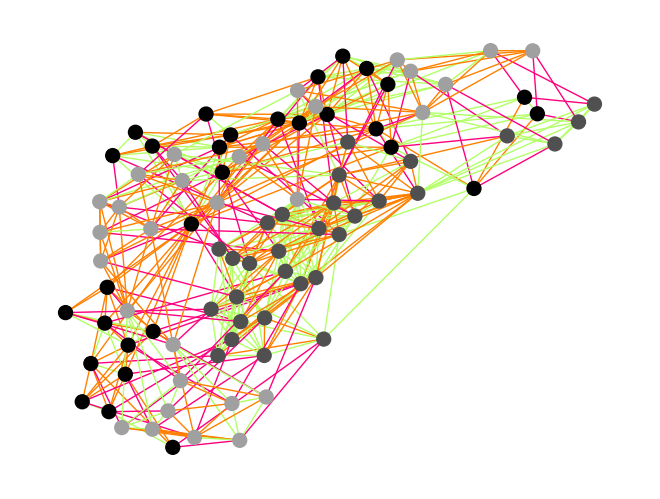

In [5]:
ts_data = utils.CsvFile(apple_path, "Close").from_csv()

v1 = get_view_strategy("slice")(start_index=60,  end_index=90)
v2 = get_view_strategy("slice")(start_index=90,  end_index=120)
v3 = get_view_strategy("slice")(start_index=150, end_index=180)

ts2g_builder  = get_ts2g_strategy_builder(method="natural_visibility")
ts2g_strategy = ts2g_builder().with_limit(1).get_strategy()

merge_builder = get_link_multigraph_strategy_builder()
link_multi    = merge_builder().time_cooccurrence()

link_nodes_builder = get_link_nodes_strategy_builder()
link_nodes         = link_nodes_builder().by_value(StrategyLinkingGraphByValueWithinRange(0.5))

pipeline3 = T2G2Pipeline()
(
    pipeline3.load_timeseries(ts_data)
            .viewing(v1)
            .add_view(v2)
            .add_view(v3)
            .to_graph(ts2g_strategy)
            .link_graphs(link_multi)
            .link_nodes_within_graphs(link_nodes)
            .combine_identical_nodes()
)

G = pipeline3.get_Graph()
draw_g(G)

Applying viewing strategy: <strategies.view.views.SliceView object at 0x7f68b42b0500>
Number of dimensions: 1; total windows: 1
Applying viewing strategy: <strategies.view.views.FixedOverlapWindow object at 0x7f6749462570>
Number of dimensions: 3; total windows: 138


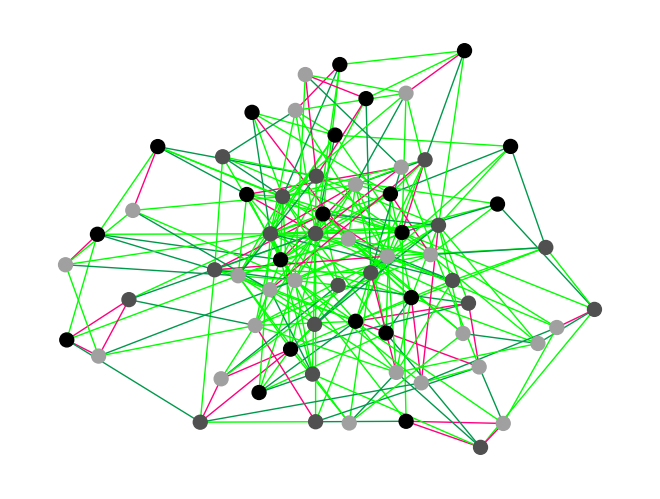

In [6]:
# Data
ts_data = utils.CsvFile(apple_path, "Close").from_csv()

# Viewing strategies
v_seg1 = get_view_strategy("slice")(start_index=60,  end_index=110)
v_seg2 = get_view_strategy("slice")(start_index=120, end_index=170)
v_seg3 = get_view_strategy("slice")(start_index=190, end_index=240)
v_sw   = get_view_strategy("sliding_window")(window_size=5, step_size=1)

# ts->graph
ts2g_builder  = get_ts2g_strategy_builder(method="natural_visibility")
ts2g_strategy = ts2g_builder().get_strategy()

# Multi-graph linking
merge_builder = get_link_multigraph_strategy_builder()
link_multi    = merge_builder().sliding_window().time_cooccurrence()

# Intra-graph linking
link_nodes_builder = get_link_nodes_strategy_builder()
link_nodes         = link_nodes_builder().seasonalities(15)

# Pipeline
pipeline4 = T2G2Pipeline()
(
    pipeline4.load_timeseries(ts_data)
            .viewing(v_seg1)
            .add_view(v_seg2)
            .add_view(v_seg3)
            .viewing(v_sw)
            .to_graph(ts2g_strategy)
            .link_graphs(link_multi)
            .combine_identical_subgraphs()
            .link_nodes_within_graphs(link_nodes)
)

# Draw
G = pipeline4.get_Graph()
draw_g(G)

Applying viewing strategy: <strategies.view.views.SliceView object at 0x7f674bf45580>
Number of dimensions: 1; total windows: 1


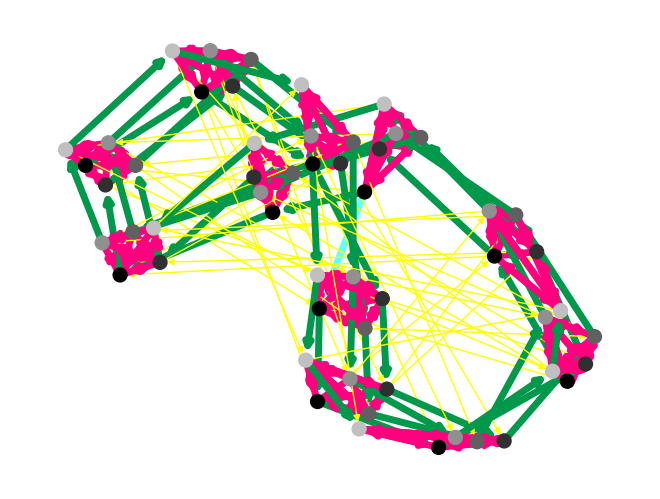

In [7]:
ts_data = utils.CsvFile(amazon_path, "Close").from_csv()

# Viewing: five slices
v1 = get_view_strategy("slice")(start_index=60,   end_index=120)
v2 = get_view_strategy("slice")(start_index=120,  end_index=180)
v3 = get_view_strategy("slice")(start_index=500,  end_index=560)
v4 = get_view_strategy("slice")(start_index=700,  end_index=760)
v5 = get_view_strategy("slice")(start_index=1000, end_index=1060)

# TS->Graph: Ordinal Partition (w=10, tau=5)
ts2g_builder  = get_ts2g_strategy_builder(method="ordinal")
ts2g_strategy = ts2g_builder(w=10, tau=5).get_strategy()

# Multi-graph linking: time_cooccurrence
merge_builder = get_link_multigraph_strategy_builder()
link_multi    = merge_builder().time_cooccurrence()

# Intra-graph linking: seasonality (period=4)
link_nodes_builder = get_link_nodes_strategy_builder()
link_nodes         = link_nodes_builder().seasonalities(4)

# Pipeline
pipeline5 = T2G2Pipeline()
(
    pipeline5.load_timeseries(ts_data)
            .viewing(v1)    
            .add_view(v2)
            .add_view(v3)
            .add_view(v4)
            .add_view(v5)
            .to_histogram(15)
            .to_graph(ts2g_strategy)
            .link_graphs(link_multi)
            .add_edge(0,2)
            .link_nodes_within_graphs(link_nodes)
)

# Add extra edge manually
G = pipeline5.get_Graph()
nodes_list = list(G.nodes())


# Draw
draw_g(G)

Applying viewing strategy: <strategies.view.views.SliceView object at 0x7f6749462c30>
Number of dimensions: 1; total windows: 1


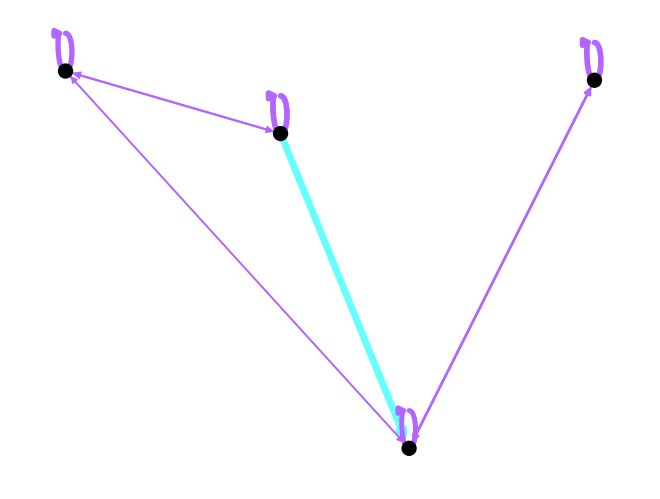

In [8]:
ts_data = utils.CsvFile(amazon_path, "Close").from_csv()

view = get_view_strategy("slice")(start_index=60, end_index=120)

ts2g_builder  = get_ts2g_strategy_builder(method="quantile")
ts2g_strategy = ts2g_builder(4, 1).get_strategy()

link_nodes_builder = get_link_nodes_strategy_builder()
link_nodes = link_nodes_builder().seasonalities(4)

pipeline6 = T2G2Pipeline()
(
    pipeline6.load_timeseries(ts_data)
            .viewing(view)
            .to_graph(ts2g_strategy)
            .add_edge(0,2)
            .link_nodes_within_graphs(link_nodes)
)

G = pipeline6.get_Graph()
draw_g(G)

Applying viewing strategy: <strategies.view.views.SliceView object at 0x7f67494b5250>
Number of dimensions: 1; total windows: 1


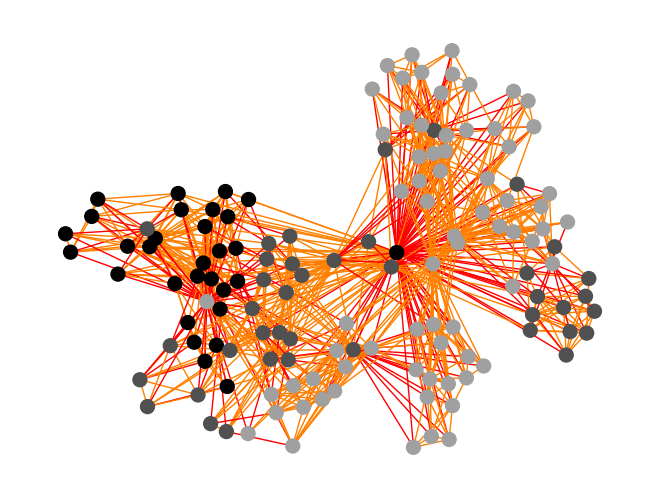

In [9]:
ts_data = utils.CsvFile(amazon_path, "Close").from_csv()

# Views: three slices
view1 = get_view_strategy("slice")(start_index=60,  end_index=90)
view2 = get_view_strategy("slice")(start_index=90,  end_index=130)
view3 = get_view_strategy("slice")(start_index=130, end_index=200)

# TS->Graph: Natural Visibility, limit=1
ts2g_builder  = get_ts2g_strategy_builder(method="natural_visibility")
ts2g_strategy = ts2g_builder().with_limit(1).get_strategy()

# Multi-graph linking: DTW
link_builder = get_link_multigraph_strategy_builder()
link_strategy = link_builder().dynamic_timewarping()

# Pipeline
pipeline_dtw = T2G2Pipeline()
(
    pipeline_dtw.load_timeseries(ts_data)
            .viewing(view1)
            .add_view(view2)
            .add_view(view3)
            .to_graph(ts2g_strategy)
            .link_graphs(link_strategy)
)

# Draw
G = pipeline_dtw.get_Graph()
draw_g(G)

# Back to time series
We can convert existing graphs back to time series based on our strategy.

Generated sequences: [[2.328125, 2.21875, 3.0, 2.375, 3.239583, 2.34375, 3.302083, 2.166667, 2.328125, 2.552083, 3.947917, 2.114583, 3.354167, 2.375, 2.375, 2.197917, 2.114583, 2.21875, 2.21875, 2.197917, 2.333333, 3.302083, 3.302083, 2.375, 2.197917, 3.6875, 2.15625, 2.166667, 2.333333, 2.197917, 2.15625, 3.40625, 2.114583, 3.239583, 3.40625, 2.166667, 2.333333, 2.197917, 2.21875, 3.354167, 3.15625, 2.166667, 2.333333, 2.328125, 2.552083, 3.239583, 3.15625, 3.09375, 2.197917, 3.09375, 3.40625, 2.328125, 3.947917, 3.6875, 3.302083, 3.354167, 2.338542, 2.552083, 2.197917, 2.166667, 2.125, 2.15625, 2.5, 2.197917, 2.338542, 3.09375, 3.0, 2.375, 2.114583, 2.21875, 3.302083, 2.114583, 2.333333, 3.09375, 3.6875, 2.197917, 2.166667, 2.338542, 2.34375, 2.333333, 3.0, 3.09375, 2.375, 3.0, 2.15625, 3.947917, 2.114583, 2.114583, 2.15625, 3.354167, 2.197917, 2.328125, 2.328125, 3.302083, 2.21875, 3.947917, 2.5, 2.114583, 2.114583, 3.947917]]


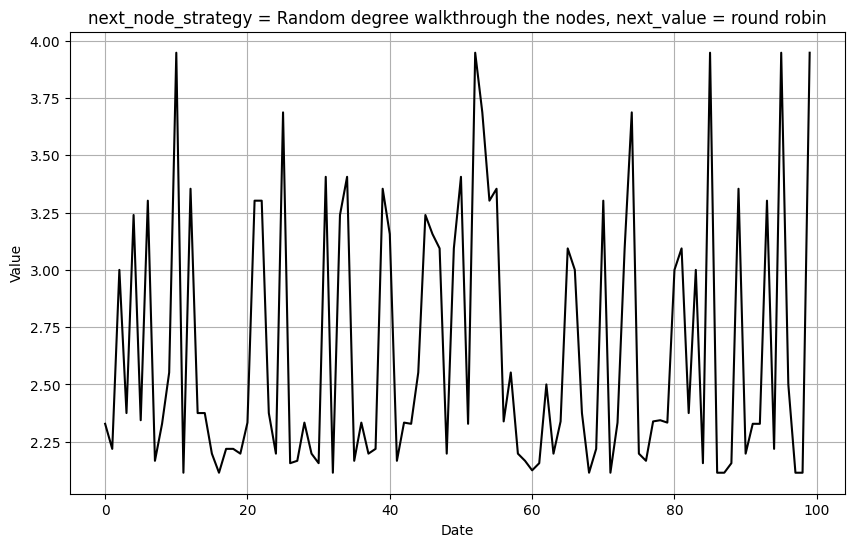

In [10]:
from strategies.g2ts import get_g2ts_strategy
from visualization import draw_sequences
from strategies.g2ts import (
    StrategySelectNextNodeRandomDegree,
    StrategyNextValueInNodeRoundRobin,
)

g2ts_cls = get_g2ts_strategy("plain") 
g2ts = (
    g2ts_cls()
    .next_node_strategy(StrategySelectNextNodeRandomDegree())
    .next_value_strategy(StrategyNextValueInNodeRoundRobin().skip_every_x_steps(1))
    .ts_length(100)
)

sequences = pipeline1.to_timeseries(g2ts).sequences
print("Generated sequences:", sequences)
draw_sequences(
    sequences, 
    node_strategy_name=g2ts._get_node_strategy_name(), 
    value_strategy_name=g2ts._get_value_strategy_name()
)

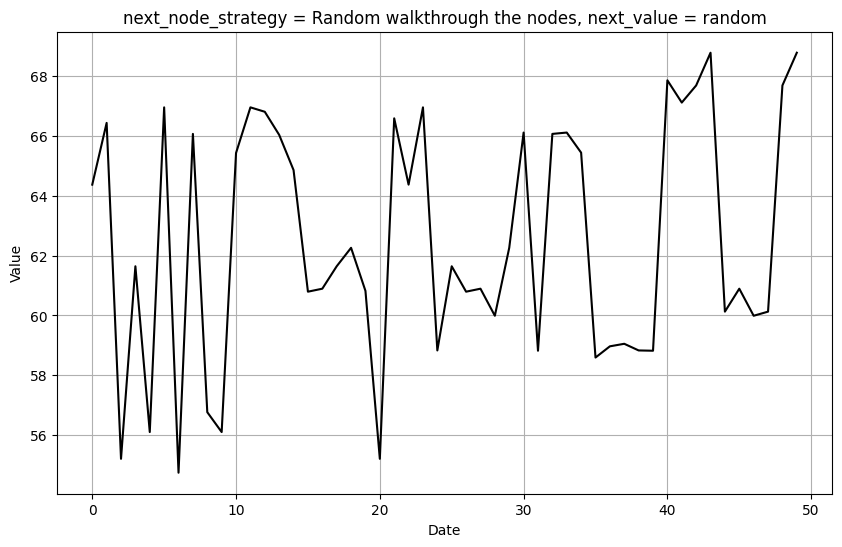

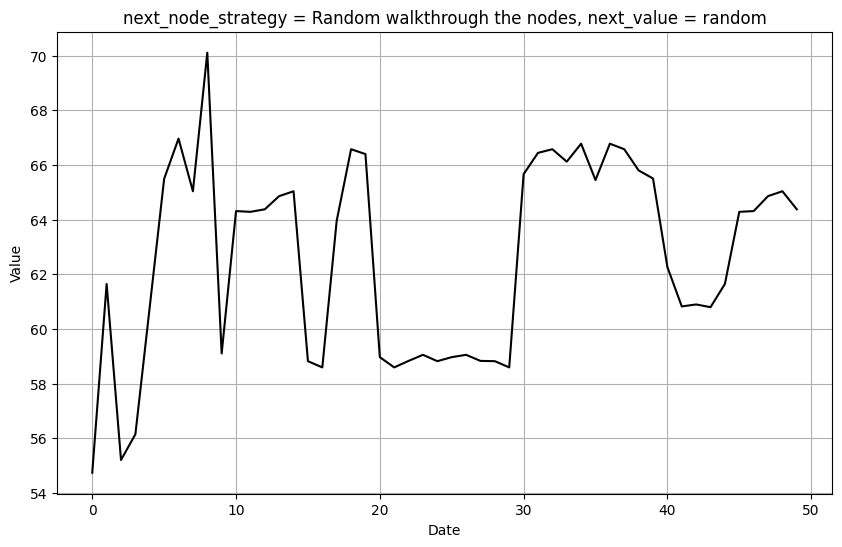

In [11]:

from strategies.g2ts import get_g2ts_strategy
from visualization import draw_sequences
from strategies.g2ts import (
    StrategySelectNextNodeRandomly,
    StrategyNextValueInNodeRandomForSlidingWindow,
)

g2ts_cls = get_g2ts_strategy("sliding_window")
g2ts = (
    g2ts_cls()
    .next_node_strategy(StrategySelectNextNodeRandomly())
    .next_value_strategy(StrategyNextValueInNodeRandomForSlidingWindow().skip_every_x_steps(1))
    .ts_length(50)
)

sequences = pipeline2.to_timeseries(g2ts).sequences

draw_sequences(
    sequences,
    node_strategy_name=g2ts._get_node_strategy_name(),
    value_strategy_name=g2ts._get_value_strategy_name()
)
g2ts_cls = get_g2ts_strategy("sliding_window")
g2ts = (
    g2ts_cls()
    .next_node_strategy(StrategySelectNextNodeRandomly())
    .next_value_strategy(StrategyNextValueInNodeRandomForSlidingWindow().skip_every_x_steps(1))
    .ts_length(50)
)

sequences = pipeline2.to_timeseries(g2ts).sequences


draw_sequences(
    sequences,
    node_strategy_name=g2ts._get_node_strategy_name(),
    value_strategy_name=g2ts._get_value_strategy_name()
)

We can also convert our multivriate graphs back to multiple time series.

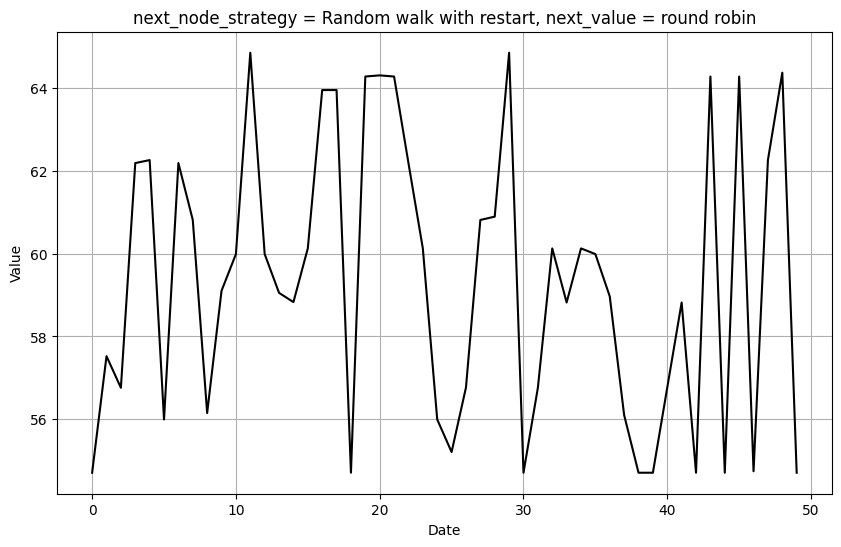

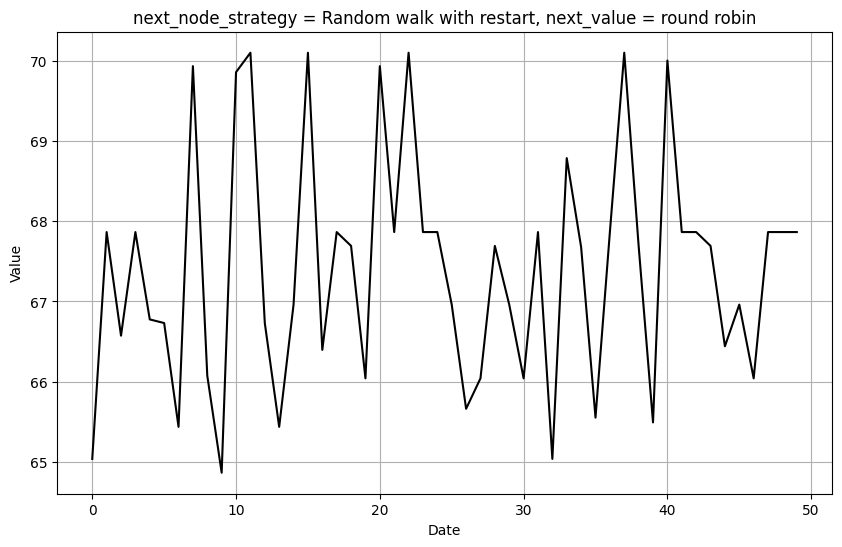

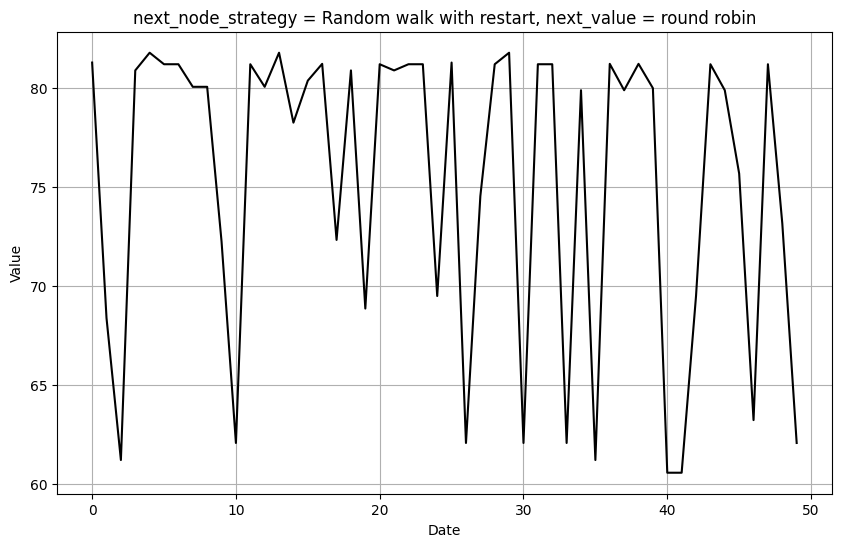

In [12]:
from strategies.g2ts import get_g2ts_strategy
from visualization import draw_sequences
from strategies.g2ts import (
    StrategySelectNextNodeRandomWithRestart,
    StrategyNextValueInNodeRoundRobin,
)

g2ts_cls = get_g2ts_strategy("plain")
g2ts = (
    g2ts_cls()
    .next_node_strategy(StrategySelectNextNodeRandomWithRestart().change_graphs_every_x_steps(2))
    .next_value_strategy(StrategyNextValueInNodeRoundRobin().skip_every_x_steps(1))
    .ts_length(50)
)

sequences = pipeline3.to_timeseries(g2ts).sequences
draw_sequences(
    sequences,
    node_strategy_name=g2ts._get_node_strategy_name(),
    value_strategy_name=g2ts._get_value_strategy_name()
)

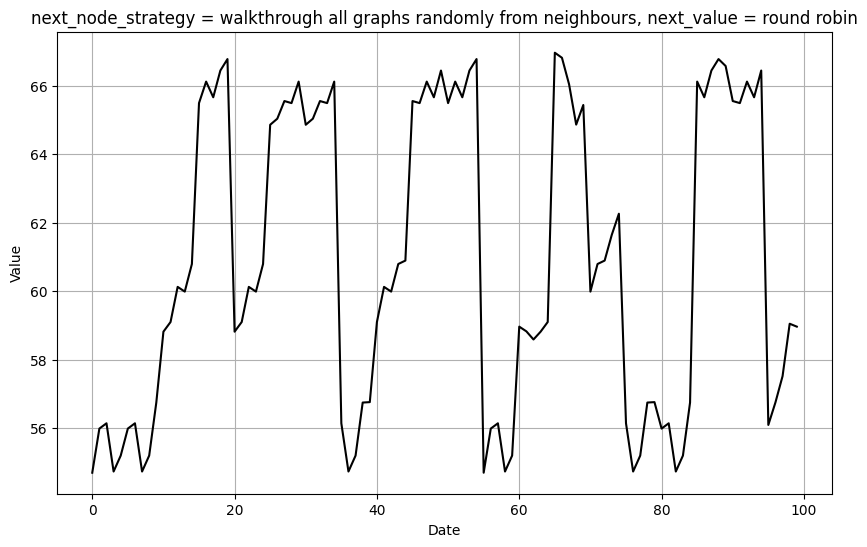

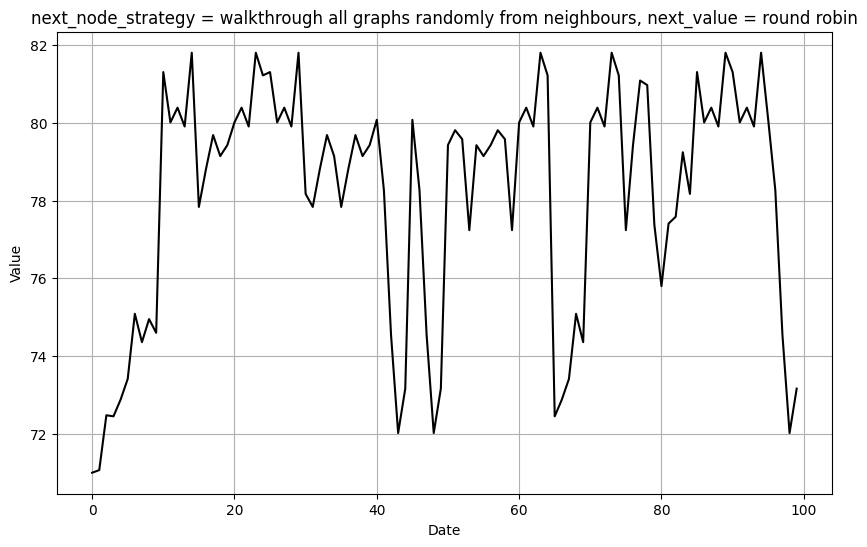

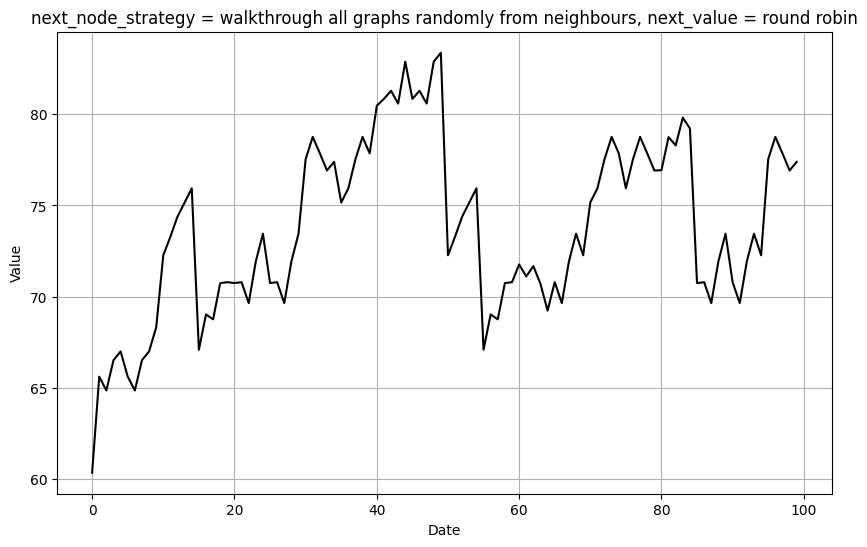

In [13]:
from strategies.g2ts import get_g2ts_strategy
from visualization import draw_sequences
from strategies.g2ts import (
    StrategySelectNextNodeRandomlyFromNeighboursAcrossGraphs,
    StrategyNextValueInNodeRoundRobinForSlidingWindow,
)

g2ts_cls = get_g2ts_strategy("sliding_window")
g2ts = (
    g2ts_cls()
    .next_node_strategy(StrategySelectNextNodeRandomlyFromNeighboursAcrossGraphs())
    .next_value_strategy(StrategyNextValueInNodeRoundRobinForSlidingWindow())
    .ts_length(100)
)

sequences = pipeline4.to_timeseries(g2ts).sequences
draw_sequences(
    sequences,
    node_strategy_name=g2ts._get_node_strategy_name(),
    value_strategy_name=g2ts._get_value_strategy_name()
)

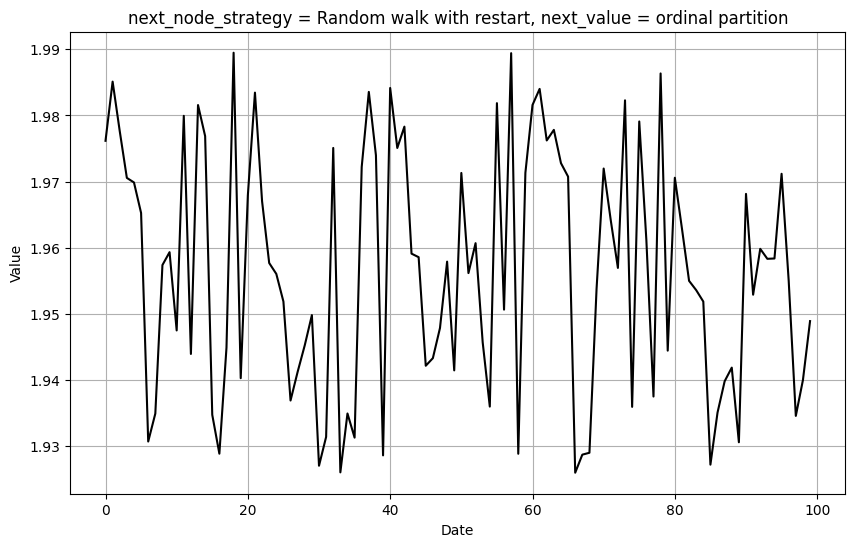

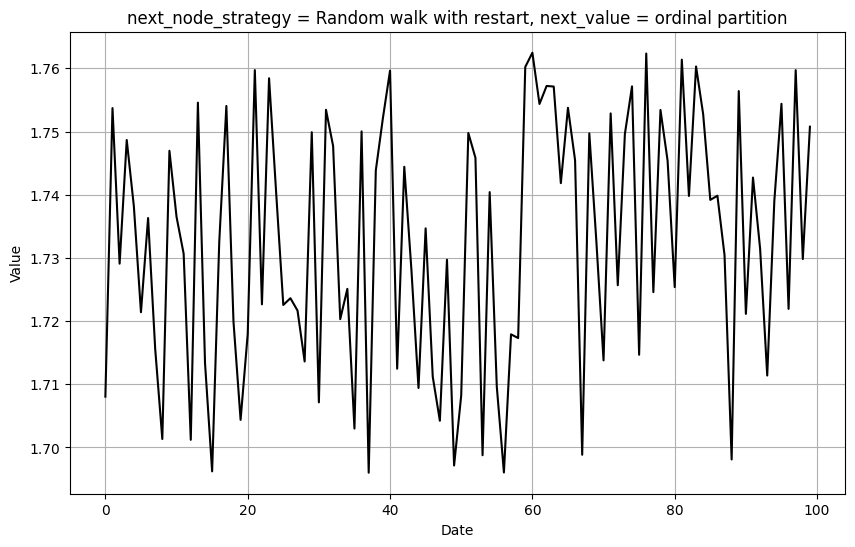

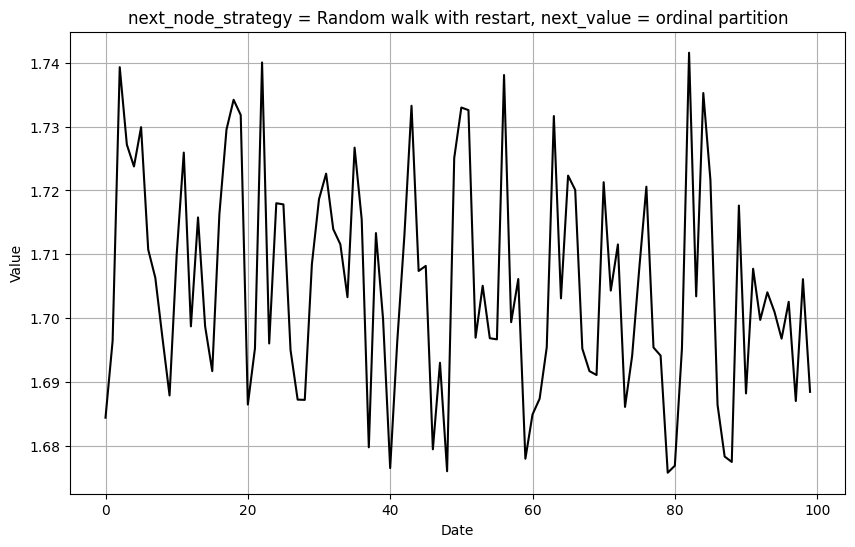

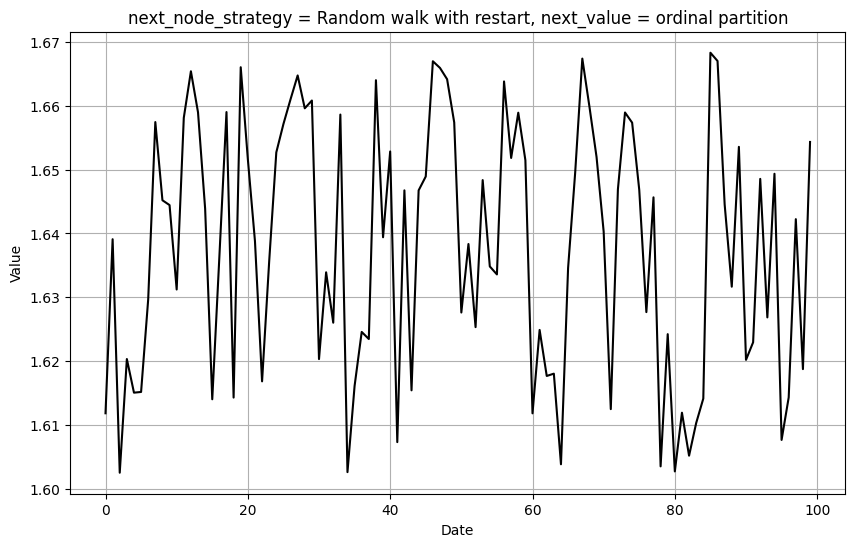

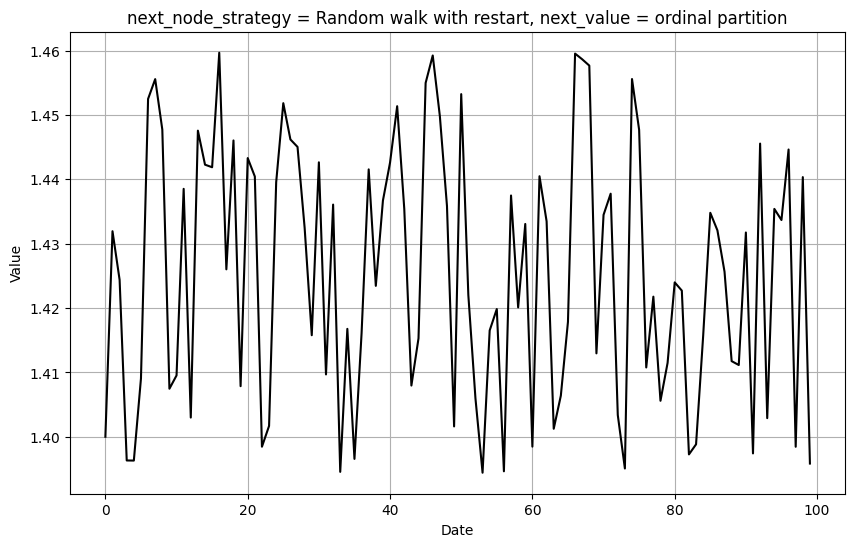

In [14]:
from strategies.g2ts import get_g2ts_strategy
from visualization import draw_sequences
from strategies.g2ts import (
    StrategySelectNextNodeRandomWithRestart,
    StrategyNextValueInNodeOrdinalPartition,
)

g2ts_cls = get_g2ts_strategy("ordinal_partition")
g2ts = (
    g2ts_cls()
    .next_node_strategy(StrategySelectNextNodeRandomWithRestart())
    .next_value_strategy(StrategyNextValueInNodeOrdinalPartition())
    .ts_length(100)
)

sequences = pipeline5.to_timeseries(g2ts).sequences
draw_sequences(
    sequences,
    node_strategy_name=g2ts._get_node_strategy_name(),
    value_strategy_name=g2ts._get_value_strategy_name()
)

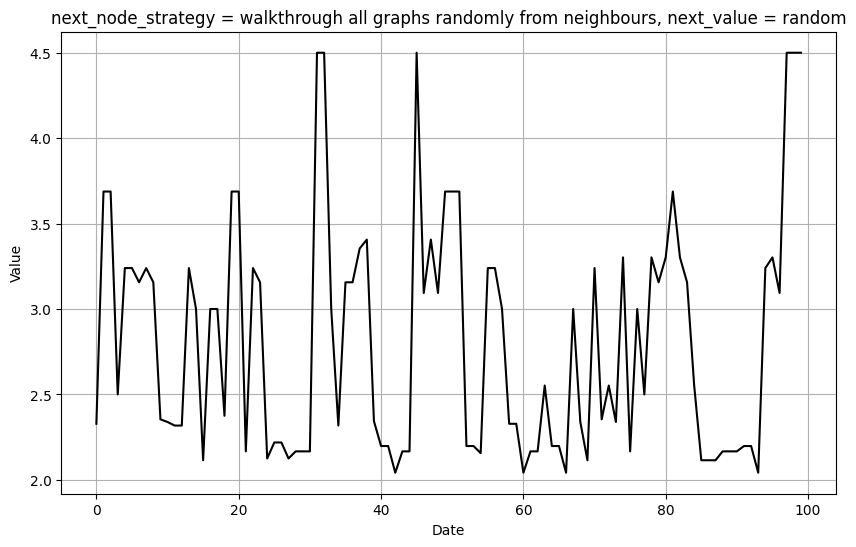

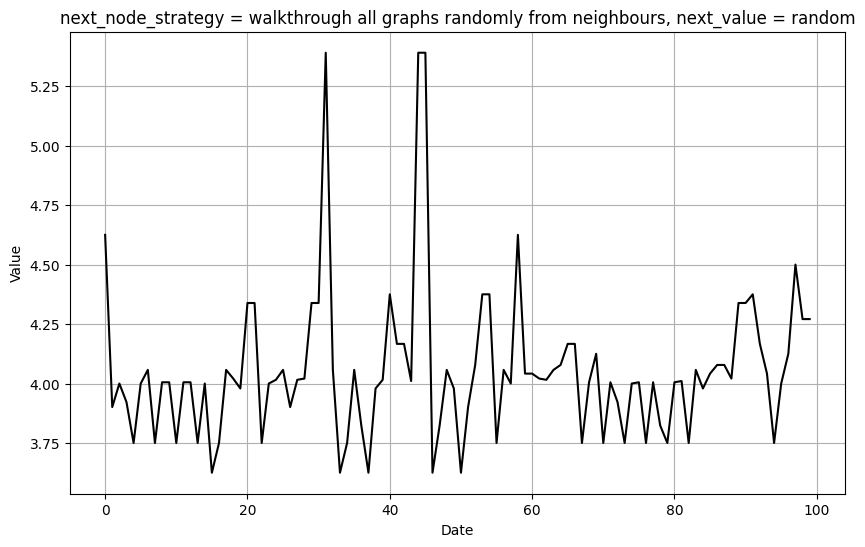

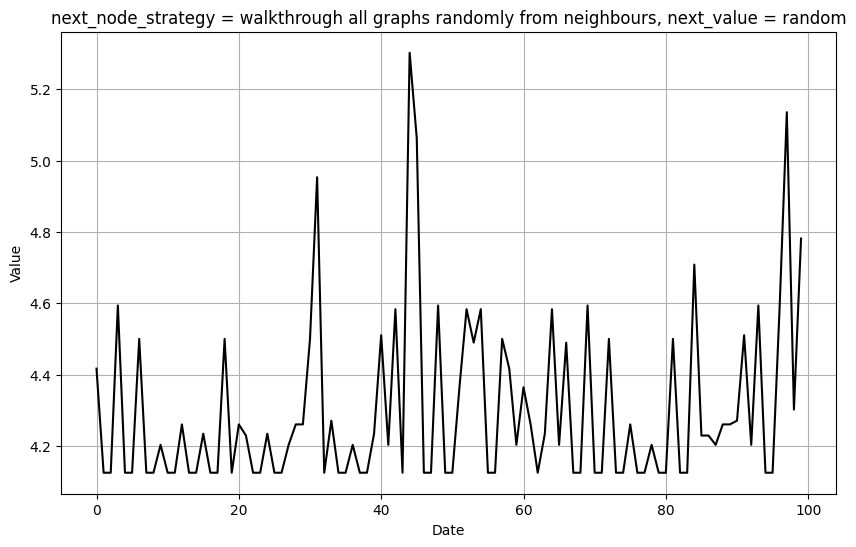

In [15]:
from strategies.g2ts import get_g2ts_strategy
from visualization import draw_sequences
from strategies.g2ts import (
    StrategySelectNextNodeRandomlyFromNeighboursAcrossGraphs,
    StrategyNextValueInNodeRandom,
)

g2ts_cls = get_g2ts_strategy("plain")
g2ts = (
    g2ts_cls()
    .next_node_strategy(StrategySelectNextNodeRandomlyFromNeighboursAcrossGraphs())
    .next_value_strategy(StrategyNextValueInNodeRandom())
    .ts_length(100)
)

sequences = pipeline_dtw.to_timeseries(g2ts).sequences
draw_sequences(
    sequences,
    node_strategy_name=g2ts._get_node_strategy_name(),
    value_strategy_name=g2ts._get_value_strategy_name()
)